## <div align="center"> LAB IS794 Deep Learning </div>
## <div align="center"> PROJECT: Preprocessing Data Audio Musik Tradisional Indonesia</div>
#### <div align="center"> Odd Semester 2026/2027 </div>
---

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.dirname(os.getcwd()))

import datetime
import uuid

In [2]:
import datetime
import uuid

studentName = "Christian Zoe Beru Tena"
studentNIM = "00000108336"
studentClass = "IS794-CL"

In [3]:
myDate = datetime.datetime.now()
myDevice = str(uuid.uuid1())

print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("Class: \t\t{}".format(studentClass))
print("Start: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Christian Zoe Beru Tena
NIM: 		00000108336
Class: 		IS794-CL
Start: 		2026-10-04 02:47:36.325153
Device ID: 	4871594c-bf63-11f1-8077-107c61abb1ed


---

### Enter Lab Code Here:

*(Give the number or each question, according to the module. If the question include a question, answer below your code with text or comment(s).)*

## <div align="center"> Preprocessing Dataset Audio Musik Tradisional untuk HuBERT & Wav2Vec 2.0 </div>

Notebook ini menerapkan rekomendasi dari `EDA_Musik_Tradisional.ipynb`:

1. Standardisasi audio → mono (rata-rata channel) + resample 16 kHz.
2. Strategi label `regional` (7 klaster, default) atau `provinsi` (drop kelas terlalu kecil).
3. Split **level lagu** (70/15/15, stratified, seed tetap) **sebelum** chunking → anti *data leakage*.
4. Segmentasi chunk 5 detik (80.000 sampel), overlap hanya di train, buang chunk hening.
5. Simpan `.wav`, `metadata.csv`, dan `class_weights.json`.
6. Fungsi augmentasi on-the-fly (khusus train).
7. Validasi hasil + ringkasan.

> Belum ada training maupun load model pre-trained di notebook ini.

### 0. CONFIG — Seluruh Parameter Preprocessing

Semua parameter dikumpulkan di satu cell. Untuk ganti strategi label cukup ubah `LABEL_MODE`.
Output tiap mode disimpan di folder terpisah supaya tidak saling menimpa.

In [4]:
# ======================= CONFIG =======================
DATA_DIR        = "data"                 # folder audio asli (38 subfolder provinsi)
LABEL_MODE      = "regional"             # "regional" (default, 7 klaster) atau "provinsi"
OUTPUT_DIR      = "processed" if LABEL_MODE == "regional" else "processed_provinsi"

TARGET_SR       = 16_000                 # sample rate target HuBERT / Wav2Vec 2.0
CHUNK_SEC       = 5.0                    # panjang chunk (detik)
CHUNK_SAMPLES   = int(TARGET_SR * CHUNK_SEC)   # 80.000 sampel

TRAIN_OVERLAP    = 0.50                  # overlap chunk train (kelas mayoritas)
MINORITY_OVERLAP = 0.75                  # overlap lebih tinggi untuk kelas minoritas (train saja)
MINORITY_MAX_TRAIN_SONGS = 40            # kelas dgn jumlah lagu train < nilai ini dianggap minoritas
EVAL_OVERLAP     = 0.0                   # val/test tanpa overlap

MIN_LAST_CHUNK_RATIO = 0.5               # sisa akhir >= 50% (2,5 s) di-zero-pad, kalau kurang di-drop
SILENCE_RMS_THRESHOLD = 1e-3             # chunk dengan RMS < ini dianggap hening & dibuang

SPLIT_RATIOS    = {"train": 0.70, "val": 0.15, "test": 0.15}
RANDOM_STATE    = 42
MIN_SONGS_PER_CLASS = 5                  # mode provinsi: minimal lagu agar bisa 1 lagu/split (3/1/1)

FORCE_REPROCESS = False                  # True = hapus & proses ulang meski output sudah ada

# Augmentasi (on-the-fly, train saja)
AUG_PITCH_SEMITONES = 2.0                # pitch shift acak di [-2, +2] semitone
AUG_STRETCH_RANGE   = (0.95, 1.05)       # time stretch
AUG_SNR_DB_RANGE    = (20.0, 30.0)       # noise injection
AUG_PROB            = 0.5                # peluang tiap augmentasi diterapkan

assert LABEL_MODE in ("regional", "provinsi")
assert abs(sum(SPLIT_RATIOS.values()) - 1.0) < 1e-9
print(f"LABEL_MODE={LABEL_MODE} | OUTPUT_DIR={OUTPUT_DIR} | CHUNK={CHUNK_SAMPLES} sampel @ {TARGET_SR} Hz")

LABEL_MODE=regional | OUTPUT_DIR=processed | CHUNK=80000 sampel @ 16000 Hz


### 1. Import Library & Setup FFmpeg

Sama seperti notebook EDA: direktori binary FFmpeg dari environment conda didaftarkan ke `PATH`
karena `torchaudio` memakai backend FFmpeg untuk mendekode `.m4a` (AAC). `soundfile` dipakai untuk menulis `.wav`.

In [5]:
import os, sys, glob, json, re, random, shutil, warnings

for p in [r"C:\Users\chris\anaconda3\envs\deeplearning\Library\bin", r"C:\Users\chris\anaconda3\Library\bin"]:
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + ";" + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchaudio
import torchaudio.functional as AF
import librosa
import librosa.display
import soundfile as sf
from tqdm.auto import tqdm
from IPython.display import Audio, display

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE); torch.manual_seed(RANDOM_STATE)

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | torchaudio {torchaudio.__version__} | librosa {librosa.__version__}")
print("Backend torchaudio:", torchaudio.list_audio_backends())

Python 3.10.13 | torch 2.5.1+cu121 | torchaudio 2.5.1+cu121 | librosa 0.11.0
Backend torchaudio: ['ffmpeg', 'soundfile']


C:\Users\chris\anaconda3\envs\deeplearning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2. Inventaris Berkas & Pembuatan `song_id`

Setiap file `.m4a` diberi `song_id` unik = `<provinsi>__<nama file>`. `song_id` inilah yang menjadi unit split
sehingga semua chunk dari satu lagu pasti berada di split yang sama.

In [6]:
all_provinces = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))

def make_song_id(prov, fname):
    stem = os.path.splitext(fname)[0]
    return re.sub(r"[^0-9A-Za-z_\-]+", "_", f"{prov}__{stem}")

records = []
for prov in all_provinces:
    for fname in sorted(os.listdir(os.path.join(DATA_DIR, prov))):
        if fname.lower().endswith(".m4a"):
            records.append({"song_id": make_song_id(prov, fname),
                            "original_file": os.path.join(DATA_DIR, prov, fname).replace("\\", "/"),
                            "provinsi": prov})
df_songs = pd.DataFrame(records)
assert df_songs["song_id"].is_unique, "song_id harus unik"

prov_counts = df_songs["provinsi"].value_counts().reindex(all_provinces, fill_value=0)
print(f"{len(all_provinces)} folder provinsi, {len(df_songs)} rekaman.")
print("Folder kosong:", prov_counts[prov_counts == 0].index.tolist())

38 folder provinsi, 855 rekaman.
Folder kosong: ['Papua_Pegunungan']


### 3. Strategi Label (`regional` vs `provinsi`)

- **`regional`** (default): 38 provinsi digabung ke 7 klaster budaya. Folder kosong `Papua_Pegunungan` otomatis terserap ke klaster Papua,
  dan provinsi dengan < 5 lagu tidak lagi menjadi kelas tunggal.
- **`provinsi`**: folder kosong dan provinsi dengan < `MIN_SONGS_PER_CLASS` lagu di-drop, karena tidak bisa dibagi
  minimal 1 lagu per split (train/val/test).

Tabel di bawah menampilkan mapping provinsi → klaster beserta jumlah lagunya.

In [7]:
PROVINCE_TO_REGION = {
    "Aceh": "Sumatera", "Sumatera_Utara": "Sumatera", "Sumatera_Barat": "Sumatera", "Riau": "Sumatera",
    "Kepulauan_Riau": "Sumatera", "Jambi": "Sumatera", "Sumatera_Selatan": "Sumatera",
    "Kepulauan_Bangka_Belitung": "Sumatera", "Bengkulu": "Sumatera", "Lampung": "Sumatera",
    "Banten": "Jawa", "Jakarta": "Jawa", "Jawa_Barat": "Jawa", "Jawa_Tengah": "Jawa",
    "Yogyakarta": "Jawa", "Jawa_Timur": "Jawa",
    "Bali": "Bali_Nusa_Tenggara", "Nusa_Tenggara_Barat": "Bali_Nusa_Tenggara", "Nusa_Tenggara_Timur": "Bali_Nusa_Tenggara",
    "Kalimantan_Barat": "Kalimantan", "Kalimantan_Tengah": "Kalimantan", "Kalimantan_Selatan": "Kalimantan",
    "Kalimantan_Timur": "Kalimantan", "Kalimantan_Utara": "Kalimantan",
    "Sulawesi_Utara": "Sulawesi", "Gorontalo": "Sulawesi", "Sulawesi_Tengah": "Sulawesi",
    "Sulawesi_Barat": "Sulawesi", "Sulawesi_Selatan": "Sulawesi", "Sulawesi_Tenggara": "Sulawesi",
    "Maluku": "Maluku", "Maluku_Utara": "Maluku",
    "Papua": "Papua", "Papua_Barat": "Papua", "Papua_Selatan": "Papua", "Papua_Tengah": "Papua",
    "Papua_Pegunungan": "Papua", "Papua_Barat_Daya": "Papua",
}
missing = set(all_provinces) - set(PROVINCE_TO_REGION)
assert not missing, f"Provinsi belum dipetakan: {missing}"

df_map = (pd.DataFrame({"provinsi": all_provinces})
          .assign(klaster=lambda d: d["provinsi"].map(PROVINCE_TO_REGION),
                  jumlah_lagu=lambda d: d["provinsi"].map(prov_counts))
          .sort_values(["klaster", "provinsi"]).reset_index(drop=True))
display(df_map)
display(df_map.groupby("klaster")["jumlah_lagu"].agg(jumlah_provinsi="count", jumlah_lagu="sum")
        .sort_values("jumlah_lagu", ascending=False))

,provinsi,klaster,jumlah_lagu
0,Bali,Bali_Nusa_Tenggara,15
1,Nusa_Tenggara_Barat,Bali_Nusa_Tenggara,9
2,Nusa_Tenggara_Timur,Bali_Nusa_Tenggara,78
3,Banten,Jawa,5
4,Jakarta,Jawa,27
5,Jawa_Barat,Jawa,57
6,Jawa_Tengah,Jawa,38
7,Jawa_Timur,Jawa,42
8,Yogyakarta,Jawa,10
9,Kalimantan_Barat,Kalimantan,49


,jumlah_provinsi,jumlah_lagu
klaster,,
Sumatera,10,279
Jawa,6,179
Kalimantan,5,120
Bali_Nusa_Tenggara,3,102
Sulawesi,6,100
Papua,6,38
Maluku,2,37


Penerapan mode label. Pada mode `provinsi`, daftar kelas yang di-drop ditampilkan.

In [8]:
dropped_classes = []
if LABEL_MODE == "regional":
    df_songs["label"] = df_songs["provinsi"].map(PROVINCE_TO_REGION)
else:
    df_songs["label"] = df_songs["provinsi"]
    small = prov_counts[prov_counts < MIN_SONGS_PER_CLASS]
    dropped_classes = small.index.tolist()
    display(small.rename("jumlah_lagu").to_frame().assign(alasan=lambda d: np.where(
        d["jumlah_lagu"] == 0, "folder kosong", f"< {MIN_SONGS_PER_CLASS} lagu (tidak bisa di-split)")))

df_used = df_songs[~df_songs["provinsi"].isin(dropped_classes)].reset_index(drop=True)
CLASS_NAMES = sorted(df_used["label"].unique())
print(f"Mode {LABEL_MODE}: {len(CLASS_NAMES)} kelas, {len(df_used)} lagu dipakai, "
      f"{len(df_songs) - len(df_used)} lagu di-drop, kelas di-drop: {dropped_classes or '-'}")

Mode regional: 7 kelas, 855 lagu dipakai, 0 lagu di-drop, kelas di-drop: -


### 4. Split Train/Val/Test di Level Lagu (Sebelum Chunking)

Split dilakukan per kelas (stratified) terhadap `song_id` dengan `RANDOM_STATE` tetap. Implementasi manual dipakai
(bukan `train_test_split` dua tahap) agar kelas kecil tetap mendapat minimal 1 lagu di val dan test.
Hasil split disimpan ke `song_split.csv` sehingga bisa direproduksi.

In [9]:
def stratified_song_split(df, label_col, ratios, seed):
    rng = np.random.RandomState(seed)
    parts = []
    for label, grp in df.groupby(label_col, sort=True):
        idx = grp.index.to_numpy().copy()
        rng.shuffle(idx)
        n = len(idx)
        n_test = max(1, int(round(n * ratios["test"])))
        n_val = max(1, int(round(n * ratios["val"])))
        assert n - n_test - n_val >= 1, f"Kelas {label} terlalu kecil untuk di-split ({n} lagu)"
        parts += [(i, "test") for i in idx[:n_test]]
        parts += [(i, "val") for i in idx[n_test:n_test + n_val]]
        parts += [(i, "train") for i in idx[n_test + n_val:]]
    out = df.copy()
    out.loc[[i for i, _ in parts], "split"] = [s for _, s in parts]
    return out

df_used = stratified_song_split(df_used, "label", SPLIT_RATIOS, RANDOM_STATE)
os.makedirs(OUTPUT_DIR, exist_ok=True)
df_used.to_csv(os.path.join(OUTPUT_DIR, "song_split.csv"), index=False)

# Anti leakage di level lagu
assert df_used.groupby("song_id")["split"].nunique().max() == 1
song_split_table = df_used.pivot_table(index="label", columns="split", values="song_id",
                                       aggfunc="count", fill_value=0)[["train", "val", "test"]]
song_split_table["total"] = song_split_table.sum(axis=1)
display(song_split_table)
print(df_used["split"].value_counts(normalize=True).round(3).to_dict())

split,train,val,test,total
label,,,,
Bali_Nusa_Tenggara,72,15,15,102
Jawa,125,27,27,179
Kalimantan,84,18,18,120
Maluku,25,6,6,37
Papua,26,6,6,38
Sulawesi,70,15,15,100
Sumatera,195,42,42,279


{'train': 0.698, 'val': 0.151, 'test': 0.151}


### 5. Fungsi Load, Standardisasi, dan Segmentasi

- **Load & standardisasi**: `torchaudio.load` → rata-rata channel (mono) → `Resample` ke 16 kHz (resampler di-cache per sample rate asal).
  File yang gagal didekode di-skip dan dicatat di `corrupt_files.log`.
- **Segmentasi**: hop = `CHUNK_SAMPLES × (1 − overlap)`.
  - Train: overlap 50%, kelas minoritas (lagu train < `MINORITY_MAX_TRAIN_SONGS`) 75%.
  - Val/Test: tanpa overlap.
- **Aturan chunk terakhir**: jika sisa ≥ 50% panjang chunk (≥ 2,5 s) → *zero-pad* sampai 80.000 sampel; jika kurang → di-drop
  (terlalu banyak padding hening akan menyesatkan model). Pada train dengan overlap, chunk terakhir hanya dibuat bila sisa ekor lagu belum tercakup.
- **Chunk hening**: RMS < `SILENCE_RMS_THRESHOLD` dibuang (biasanya intro/outro senyap).

In [10]:
_resamplers = {}

def load_standardized(path, target_sr=TARGET_SR):
    """Load audio -> mono float32 1D tensor @ target_sr."""
    wav, sr = torchaudio.load(path)
    wav = wav.mean(dim=0)                       # (L+R)/2
    if sr != target_sr:
        if sr not in _resamplers:
            _resamplers[sr] = torchaudio.transforms.Resample(sr, target_sr)
        wav = _resamplers[sr](wav)
    return wav.contiguous()

def segment_waveform(wav, overlap, chunk=CHUNK_SAMPLES):
    """Return list of (start_sample, chunk_tensor, padded_flag)."""
    hop = max(1, int(round(chunk * (1 - overlap))))
    n = wav.shape[0]
    out, last_end = [], 0
    start = 0
    while start + chunk <= n:
        out.append((start, wav[start:start + chunk], False))
        last_end = start + chunk
        start += hop
    tail_start = start if overlap == 0 else last_end
    remain = n - tail_start
    if remain >= MIN_LAST_CHUNK_RATIO * chunk:
        seg = torch.nn.functional.pad(wav[tail_start:], (0, chunk - remain))
        out.append((tail_start, seg, True))
    return out

def is_silent(seg, thr=SILENCE_RMS_THRESHOLD):
    return torch.sqrt(torch.mean(seg ** 2)).item() < thr

train_song_counts = df_used[df_used["split"] == "train"]["label"].value_counts()
MINORITY_CLASSES = sorted(train_song_counts[train_song_counts < MINORITY_MAX_TRAIN_SONGS].index)

def overlap_for(split, label):
    if split != "train":
        return EVAL_OVERLAP
    return MINORITY_OVERLAP if label in MINORITY_CLASSES else TRAIN_OVERLAP

print("Kelas minoritas (overlap train 75%):", MINORITY_CLASSES)
# Sanity check segmentasi pada sinyal dummy 12 detik
for ov in (0.0, 0.5):
    segs = segment_waveform(torch.randn(12 * TARGET_SR), ov)
    print(f"overlap={ov}: {[(s / TARGET_SR, p) for s, _, p in segs]}")

Kelas minoritas (overlap train 75%): ['Maluku', 'Papua']
overlap=0.0: [(0.0, False), (5.0, False)]
overlap=0.5: [(0.0, False), (2.5, False), (5.0, False)]


### 6. Proses Utama: Chunking & Penyimpanan `.wav`

Setiap lagu diproses satu kali; hasil chunk-nya dicatat di `OUTPUT_DIR/_manifest/<song_id>.json`.
Jika manifest sudah ada, lagu di-skip → proses bisa dilanjutkan bila terhenti, dan re-run notebook tidak memproses ulang.
Set `FORCE_REPROCESS = True` untuk memproses ulang dari nol. Chunk disimpan sebagai WAV PCM 16-bit 16 kHz di
`OUTPUT_DIR/<split>/<label>/`.

In [11]:
MANIFEST_DIR = os.path.join(OUTPUT_DIR, "_manifest")
CORRUPT_LOG = os.path.join(OUTPUT_DIR, "corrupt_files.log")

if FORCE_REPROCESS:
    for sp in ("train", "val", "test", "_manifest"):
        shutil.rmtree(os.path.join(OUTPUT_DIR, sp), ignore_errors=True)
os.makedirs(MANIFEST_DIR, exist_ok=True)

corrupt, n_skipped = [], 0
for row in tqdm(df_used.itertuples(index=False), total=len(df_used), desc="Chunking"):
    man_path = os.path.join(MANIFEST_DIR, f"{row.song_id}.json")
    if os.path.exists(man_path):
        n_skipped += 1
        continue
    try:
        wav = load_standardized(row.original_file)
    except Exception as e:
        corrupt.append(f"{row.original_file}\t{type(e).__name__}: {e}")
        continue
    out_dir = os.path.join(OUTPUT_DIR, row.split, row.label)
    os.makedirs(out_dir, exist_ok=True)
    chunks, n_silent = [], 0
    for k, (start, seg, padded) in enumerate(segment_waveform(wav, overlap_for(row.split, row.label))):
        if is_silent(seg):
            n_silent += 1
            continue
        cpath = os.path.join(out_dir, f"{row.song_id}__{k:04d}.wav").replace("\\", "/")
        sf.write(cpath, seg.numpy(), TARGET_SR, subtype="PCM_16")
        chunks.append({"chunk_path": cpath, "song_id": row.song_id, "original_file": row.original_file,
                       "provinsi": row.provinsi, "label": row.label, "split": row.split,
                       "start_sec": round(start / TARGET_SR, 3), "padded": padded})
    with open(man_path, "w", encoding="utf-8") as f:
        json.dump({"song_id": row.song_id, "duration_sec": wav.shape[0] / TARGET_SR,
                   "n_silent_dropped": n_silent, "chunks": chunks}, f)

with open(CORRUPT_LOG, "a", encoding="utf-8") as f:
    for line in corrupt:
        f.write(line + "\n")
print(f"Lagu di-skip (sudah diproses): {n_skipped} | file korup baru: {len(corrupt)} (lihat {CORRUPT_LOG})")

Chunking:   0%|          | 0/855 [00:00<?, ?it/s]

Chunking:   0%|          | 1/855 [00:00<11:38,  1.22it/s]

Chunking:   0%|          | 2/855 [00:01<09:14,  1.54it/s]

Chunking:   0%|          | 3/855 [00:02<11:31,  1.23it/s]

Chunking:   0%|          | 4/855 [00:03<12:00,  1.18it/s]

Chunking:   1%|          | 5/855 [00:04<15:23,  1.09s/it]

... (848 outputs left out)

Chunking: 100%|█████████▉| 854/855 [15:19<00:00,  1.03it/s]

Chunking: 100%|██████████| 855/855 [15:20<00:00,  1.03s/it]

Chunking: 100%|██████████| 855/855 [15:20<00:00,  1.08s/it]

Lagu di-skip (sudah diproses): 0 | file korup baru: 0 (lihat processed\corrupt_files.log)


### 7. Menyusun `metadata.csv`

Seluruh manifest digabung menjadi `metadata.csv` dengan kolom wajib
`chunk_path, song_id, original_file, provinsi, label, split, start_sec` (ditambah `padded` sebagai info tambahan).
Hanya lagu yang termasuk konfigurasi saat ini yang diambil.

In [12]:
manifests = []
for sid in df_used["song_id"]:
    mp = os.path.join(MANIFEST_DIR, f"{sid}.json")
    if os.path.exists(mp):
        with open(mp, encoding="utf-8") as f:
            manifests.append(json.load(f))

META_COLS = ["chunk_path", "song_id", "original_file", "provinsi", "label", "split", "start_sec", "padded"]
df_meta = pd.DataFrame([c for m in manifests for c in m["chunks"]], columns=META_COLS)
df_meta.to_csv(os.path.join(OUTPUT_DIR, "metadata.csv"), index=False)

n_silent_total = sum(m["n_silent_dropped"] for m in manifests)
print(f"Lagu terproses: {len(manifests)}/{len(df_used)} | total chunk: {len(df_meta):,} | "
      f"chunk hening dibuang: {n_silent_total:,} | chunk ter-pad: {int(df_meta['padded'].sum()):,}")
display(df_meta.head())

Lagu terproses: 855/855 | total chunk: 78,074 | chunk hening dibuang: 248 | chunk ter-pad: 90


,chunk_path,song_id,original_file,provinsi,label,split,start_sec,padded
0,processed/train/Sumatera/Aceh__10_Saleum__0000...,Aceh__10_Saleum,data/Aceh/10_Saleum.m4a,Aceh,Sumatera,train,0.0,False
1,processed/train/Sumatera/Aceh__10_Saleum__0001...,Aceh__10_Saleum,data/Aceh/10_Saleum.m4a,Aceh,Sumatera,train,2.5,False
2,processed/train/Sumatera/Aceh__10_Saleum__0002...,Aceh__10_Saleum,data/Aceh/10_Saleum.m4a,Aceh,Sumatera,train,5.0,False
3,processed/train/Sumatera/Aceh__10_Saleum__0003...,Aceh__10_Saleum,data/Aceh/10_Saleum.m4a,Aceh,Sumatera,train,7.5,False
4,processed/train/Sumatera/Aceh__10_Saleum__0004...,Aceh__10_Saleum,data/Aceh/10_Saleum.m4a,Aceh,Sumatera,train,10.0,False


### 8. Class Weights untuk Weighted Cross-Entropy

Bobot dihitung dari **jumlah chunk train** per kelas dengan rumus invers frekuensi ter-normalisasi:
$w_c = \dfrac{N}{K \cdot n_c}$ ($N$ = total chunk train, $K$ = jumlah kelas). Disimpan bersama `label2id`
agar urutan kelas konsisten saat training.

In [13]:
train_counts = df_meta[df_meta["split"] == "train"]["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
N, K = train_counts.sum(), len(CLASS_NAMES)
class_weights = {c: float(N / (K * n)) if n > 0 else 0.0 for c, n in train_counts.items()}
label2id = {c: i for i, c in enumerate(CLASS_NAMES)}

cw_payload = {"label_mode": LABEL_MODE, "label2id": label2id,
              "id2label": {i: c for c, i in label2id.items()},
              "train_chunk_counts": {c: int(n) for c, n in train_counts.items()},
              "class_weights": class_weights,
              "weights_by_id": [class_weights[c] for c in CLASS_NAMES]}
with open(os.path.join(OUTPUT_DIR, "class_weights.json"), "w", encoding="utf-8") as f:
    json.dump(cw_payload, f, indent=2)

display(pd.DataFrame({"chunk_train": train_counts, "class_weight": pd.Series(class_weights)}).round(4))

,chunk_train,class_weight
Bali_Nusa_Tenggara,7858,1.1854
Jawa,12347,0.7544
Kalimantan,8220,1.1332
Maluku,3719,2.5046
Papua,4142,2.2488
Sulawesi,8068,1.1545
Sumatera,20849,0.4468


### 9. Augmentasi On-the-fly (Khusus Train)

Fungsi augmentasi diterapkan **saat training** di `Dataset.__getitem__` untuk split train saja — **tidak disimpan ke disk**.
Tiap transformasi diterapkan dengan peluang `AUG_PROB`:

| Augmentasi | Parameter | Implementasi |
|---|---|---|
| Pitch shift | ±2 semitone | `torchaudio.functional.pitch_shift` |
| Time stretch | 0.95–1.05× | `librosa.effects.time_stretch` + crop/pad kembali ke 80.000 sampel |
| Noise injection | SNR 20–30 dB | Gaussian noise dengan daya sesuai SNR |

In [14]:
def fix_length(x, n=CHUNK_SAMPLES):
    return x[:n] if x.shape[0] >= n else torch.nn.functional.pad(x, (0, n - x.shape[0]))

def pitch_shift(x, semitones):
    return AF.pitch_shift(x.unsqueeze(0), TARGET_SR, n_steps=semitones).squeeze(0)

def time_stretch(x, rate):
    y = librosa.effects.time_stretch(x.numpy().astype(np.float32), rate=rate)
    return fix_length(torch.from_numpy(y))

def add_noise(x, snr_db):
    p_signal = x.pow(2).mean()
    if p_signal <= 0:
        return x
    p_noise = p_signal / (10 ** (snr_db / 10))
    return x + torch.randn_like(x) * p_noise.sqrt()

def augment_train(x, rng=random):
    """x: 1D tensor (80.000). Panggil HANYA untuk sampel train saat training."""
    if rng.random() < AUG_PROB:
        x = pitch_shift(x, rng.uniform(-AUG_PITCH_SEMITONES, AUG_PITCH_SEMITONES))
    if rng.random() < AUG_PROB:
        x = time_stretch(x, rng.uniform(*AUG_STRETCH_RANGE))
    if rng.random() < AUG_PROB:
        x = add_noise(x, rng.uniform(*AUG_SNR_DB_RANGE))
    return fix_length(x).clamp(-1.0, 1.0)

Demo augmentasi pada 1 chunk train: masing-masing augmentasi ditampilkan terpisah (parameter tetap agar jelas),
lengkap dengan audio player dan mel-spectrogram. File asli di disk tidak berubah.

Sampel demo: processed/train/Sumatera/Bengkulu__131_Jibeak_Aweio__0034.wav (label=Sumatera)


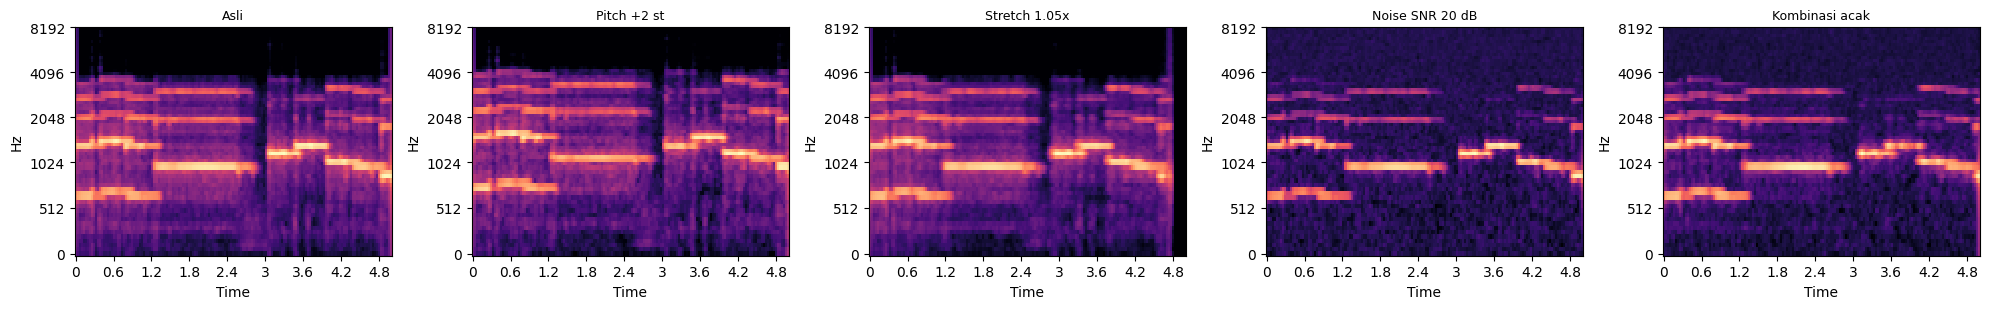

Asli


Pitch +2 st


Stretch 1.05x


Noise SNR 20 dB


Kombinasi acak


In [15]:
def plot_mel(ax, x, title):
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=np.asarray(x, dtype=np.float32), sr=TARGET_SR, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=TARGET_SR, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(title, fontsize=9)

demo_row = df_meta[df_meta["split"] == "train"].sample(1, random_state=RANDOM_STATE).iloc[0]
x0 = torch.from_numpy(sf.read(demo_row["chunk_path"], dtype="float32")[0])
variants = {"Asli": x0,
            "Pitch +2 st": pitch_shift(x0, 2.0),
            "Stretch 1.05x": time_stretch(x0, 1.05),
            "Noise SNR 20 dB": add_noise(x0, 20.0),
            "Kombinasi acak": augment_train(x0, random.Random(RANDOM_STATE))}

print(f"Sampel demo: {demo_row['chunk_path']} (label={demo_row['label']})")
fig, axes = plt.subplots(1, len(variants), figsize=(20, 3.2))
for ax, (name, x) in zip(axes, variants.items()):
    assert x.shape[0] == CHUNK_SAMPLES
    plot_mel(ax, x.numpy(), name)
plt.tight_layout(); plt.show()
for name, x in variants.items():
    print(name); display(Audio(x.numpy(), rate=TARGET_SR))

### 10. Validasi Hasil

#### 10.1 Jumlah lagu & chunk per kelas per split (sebelum vs sesudah chunking)
"Sebelum" = jumlah lagu (unit split), "Sesudah" = jumlah chunk 5 detik.

Lagu (sebelum)          Chunk (sesudah)            
split                       train val test           train   val  test
label                                                                 
Bali_Nusa_Tenggara             72  15   15            7858   919   757
Jawa                          125  27   27           12347  1339  1333
Kalimantan                     84  18   18            8220   784   893
Maluku                         25   6    6            3719   259   243
Papua                          26   6    6            4142   235   261
Sulawesi                       70  15   15            8068   709   846
Sumatera                      195  42   42           20849  2133  2160

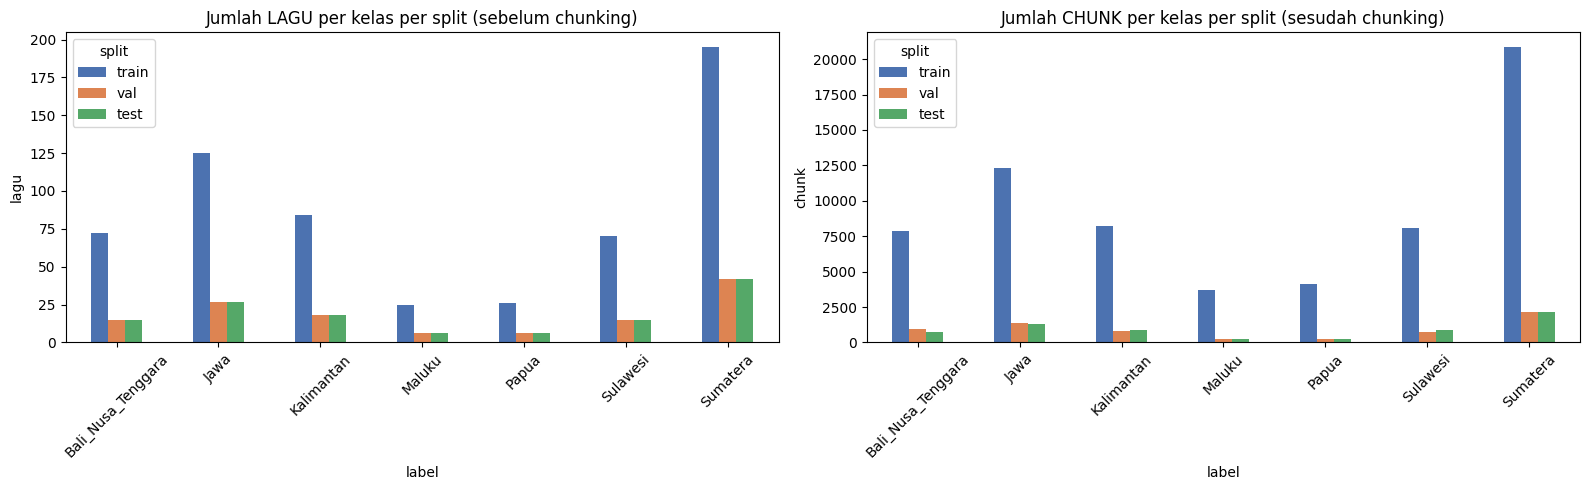

Rasio imbalance lagu (total): 7.5 : 1 | rasio imbalance chunk train: 5.6 : 1


In [16]:
chunk_table = df_meta.pivot_table(index="label", columns="split", values="chunk_path",
                                  aggfunc="count", fill_value=0).reindex(columns=["train", "val", "test"], fill_value=0)
compare = pd.concat({"Lagu (sebelum)": song_split_table[["train", "val", "test"]],
                     "Chunk (sesudah)": chunk_table}, axis=1)
display(compare)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
song_split_table[["train", "val", "test"]].plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Jumlah LAGU per kelas per split (sebelum chunking)"); axes[0].set_ylabel("lagu")
chunk_table.plot.bar(ax=axes[1], color=["#4C72B0", "#DD8452", "#55A868"])
axes[1].set_title("Jumlah CHUNK per kelas per split (sesudah chunking)"); axes[1].set_ylabel("chunk")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

ratio_before = song_split_table["total"].max() / song_split_table["total"].min()
ratio_after = train_counts.max() / train_counts.min()
print(f"Rasio imbalance lagu (total): {ratio_before:.1f} : 1 | rasio imbalance chunk train: {ratio_after:.1f} : 1")

#### 10.2 Assert anti-leakage & format chunk
- Tidak ada `song_id` yang muncul di lebih dari satu split.
- Semua chunk: 16 kHz, mono, tepat 80.000 sampel (dicek dari header WAV untuk **semua** file).

In [17]:
leak = df_meta.groupby("song_id")["split"].nunique()
assert (leak == 1).all(), f"LEAKAGE: {leak[leak > 1].index.tolist()[:5]}"
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not set(df_meta.loc[df_meta.split == a, "song_id"]) & set(df_meta.loc[df_meta.split == b, "song_id"])
print("✔ Tidak ada song_id yang bocor antar split.")

bad = []
for p in tqdm(df_meta["chunk_path"], desc="Cek format WAV"):
    info = sf.info(p)
    if not (info.samplerate == TARGET_SR and info.channels == 1 and info.frames == CHUNK_SAMPLES):
        bad.append((p, info.samplerate, info.channels, info.frames))
assert not bad, f"{len(bad)} chunk tidak sesuai format, contoh: {bad[:3]}"
print(f"✔ Semua {len(df_meta):,} chunk: {TARGET_SR} Hz, mono, {CHUNK_SAMPLES:,} sampel.")

✔ Tidak ada song_id yang bocor antar split.


Cek format WAV:   0%|          | 0/78074 [00:00<?, ?it/s]

Cek format WAV:   0%|          | 15/78074 [00:00<09:09, 141.98it/s]

Cek format WAV:   0%|          | 30/78074 [00:00<09:20, 139.12it/s]

Cek format WAV:   0%|          | 44/78074 [00:00<10:22, 125.36it/s]

Cek format WAV:   0%|          | 59/78074 [00:00<09:51, 131.81it/s]

... (5,505 outputs left out)

Cek format WAV: 100%|█████████▉| 78061/78074 [09:58<00:00, 109.29it/s]

Cek format WAV: 100%|█████████▉| 78072/78074 [09:58<00:00, 107.99it/s]

Cek format WAV: 100%|██████████| 78074/78074 [09:58<00:00, 130.48it/s]

✔ Semua 78,074 chunk: 16000 Hz, mono, 80,000 sampel.


#### 10.3 Cek sampel: putar audio & mel-spectrogram
Satu chunk acak per kelas dari split test (tanpa augmentasi).

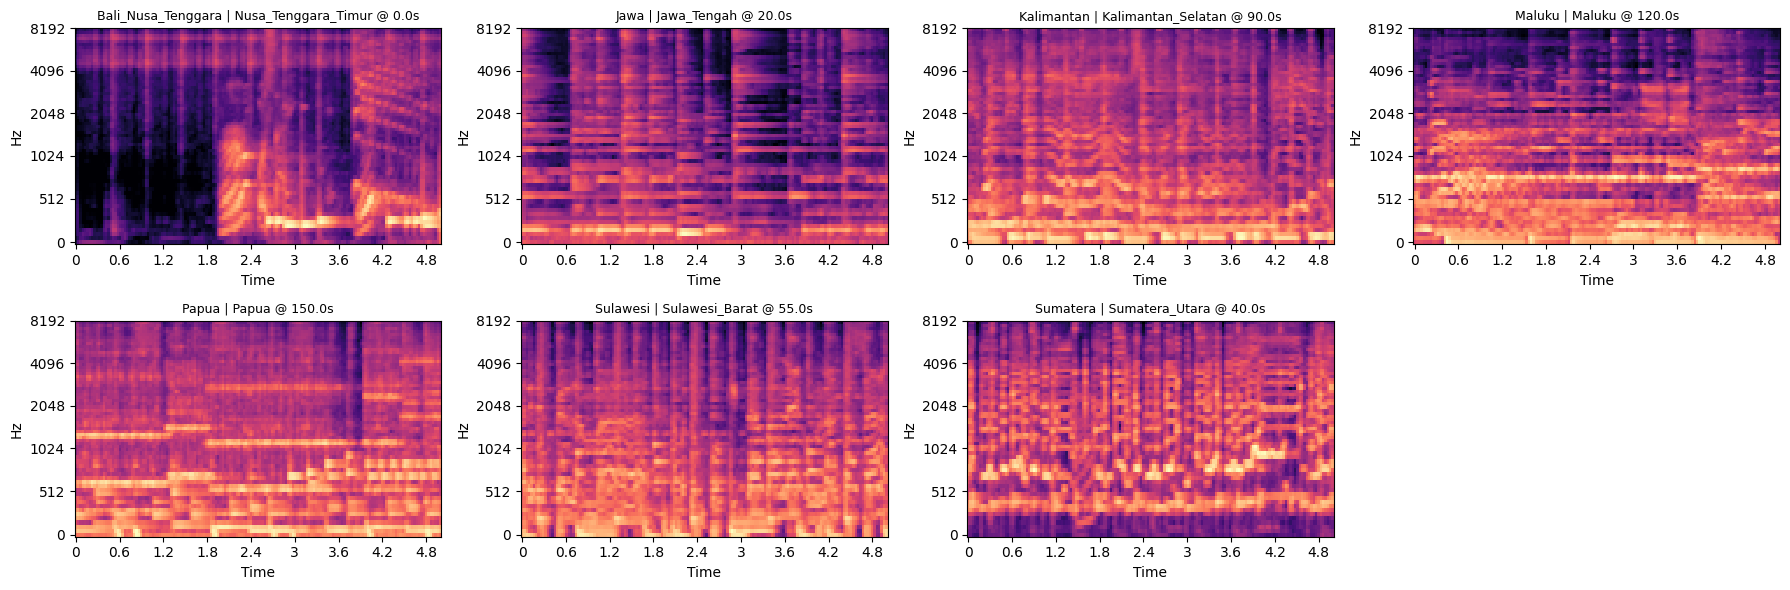

Bali_Nusa_Tenggara — Nusa_Tenggara_Timur__396_Gemu_Fa_Mi_Re__0000.wav


Jawa — Jawa_Tengah__609_West_Java_Sundanese_Mamaos__0004.wav


Kalimantan — Kalimantan_Selatan__476_Syair_Japin_Hadrah__0018.wav


Maluku — Maluku__558_Gunung_Salahatu__0024.wav


In [18]:
samples = (df_meta[df_meta["split"] == "test"].groupby("label", group_keys=False)
           .apply(lambda g: g.sample(1, random_state=RANDOM_STATE)))
ncol = min(4, len(samples)); nrow = int(np.ceil(len(samples) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.5 * ncol, 3 * nrow), squeeze=False)
for ax, (_, r) in zip(axes.flat, samples.iterrows()):
    y, _ = sf.read(r["chunk_path"], dtype="float32")
    plot_mel(ax, y, f"{r['label']} | {r['provinsi']} @ {r['start_sec']}s")
for ax in axes.flat[len(samples):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

for _, r in samples.head(4).iterrows():
    print(f"{r['label']} — {os.path.basename(r['chunk_path'])}")
    display(Audio(r["chunk_path"]))

### 11. Statistik Akhir Dataset

In [19]:
summary = {
    "Mode label": LABEL_MODE,
    "Jumlah kelas": len(CLASS_NAMES),
    "Lagu dipakai": int(df_meta["song_id"].nunique()),
    "File korup": sum(1 for _ in open(CORRUPT_LOG, encoding="utf-8")) if os.path.exists(CORRUPT_LOG) else 0,
    "Total chunk": len(df_meta),
    "Chunk train / val / test": " / ".join(str((df_meta["split"] == s).sum()) for s in ["train", "val", "test"]),
    "Chunk hening dibuang": n_silent_total,
    "Total durasi chunk (jam)": round(len(df_meta) * CHUNK_SEC / 3600, 2),
    "Ukuran output (GB)": round(sum(os.path.getsize(p) for p in df_meta["chunk_path"]) / 1e9, 2),
}
display(pd.Series(summary, name="nilai").to_frame())

,nilai
Mode label,regional
Jumlah kelas,7
Lagu dipakai,855
File korup,0
Total chunk,78074
Chunk train / val / test,65203 / 6378 / 6493
Chunk hening dibuang,248
Total durasi chunk (jam),108.44
Ukuran output (GB),12.5


----

## <div align="center"> Conclusion </div>

### Enter Your Conclusion Here:

### Ringkasan Preprocessing

**Keputusan yang diambil**
1. **Standardisasi**: semua `.m4a` (stereo 44,1/48 kHz) → mono rata-rata channel → 16 kHz via `torchaudio`. File gagal decode di-skip dan dicatat di `corrupt_files.log`.
2. **Label**: default `regional` (7 klaster: Sumatera, Jawa, Bali_Nusa_Tenggara, Kalimantan, Sulawesi, Maluku, Papua). Imbalance turun dari 78 : 1 (provinsi) menjadi ±7,5 : 1 di level lagu, dan folder kosong `Papua_Pegunungan` terserap ke Papua. Mode `provinsi` tersedia (drop 8 kelas: folder kosong + 7 provinsi < 5 lagu → 30 kelas).
3. **Split 70/15/15 di level lagu sebelum chunking** (stratified, `RANDOM_STATE=42`) → terverifikasi tidak ada `song_id` yang bocor.
4. **Segmentasi 5 detik (80.000 sampel)**: train overlap 50% (kelas minoritas Maluku & Papua 75%), val/test tanpa overlap. Sisa akhir ≥ 2,5 s di-zero-pad, < 2,5 s di-drop. Chunk dengan RMS < 1e-3 dibuang.
5. **Augmentasi** (pitch ±2 st, stretch 0,95–1,05×, noise SNR 20–30 dB) hanya on-the-fly untuk train lewat `augment_train()`.

Statistik akhir lengkap ada di tabel bagian 10–11 (output notebook).

**Catatan untuk tahap training**
- Input: baca `processed/metadata.csv`, load `chunk_path` (sudah 16 kHz, mono, 80.000 sampel) → `Wav2Vec2FeatureExtractor(sampling_rate=16000)` (dipakai juga untuk HuBERT); normalisasi zero-mean/unit-variance dilakukan oleh feature extractor. Tidak perlu resample/padding lagi.
- Panggil `augment_train()` di `Dataset.__getitem__` **hanya** untuk split train.
- Loss: `CrossEntropyLoss(weight=torch.tensor(weights_by_id))` dari `class_weights.json` (urutan sesuai `label2id`).
- VRAM 4 GB: chunk 5 s ≈ 249 frame Transformer; mulai dari batch kecil (4–8) + gradient accumulation, fp16, dan freeze feature encoder CNN.
- Metrik utama: **Macro-F1** dan **Balanced Accuracy** (plus confusion matrix). Evaluasi juga level lagu dengan agregasi (rata-rata probabilitas) seluruh chunk satu lagu.

In [20]:
# Ringkasan preprocessing ada pada markdown di atas.

----

In [21]:
print("Name: \t\t{}".format(studentName))
print("NIM: \t\t{}".format(studentNIM))
print("Class: \t\t{}".format(studentClass))
print("End: \t\t{}".format(myDate))
print("Device ID: \t{}".format(myDevice))

Name: 		Christian Zoe Beru Tena
NIM: 		00000108336
Class: 		IS794-CL
End: 		2026-10-04 02:47:36.325153
Device ID: 	4871594c-bf63-11f1-8077-107c61abb1ed


----

## <div align="center"> Reference </div>

### Input Your Reference Here  (If any):

1. **Baevski, A., Zhou, Y., Mohamed, A., & Auli, M. (2020).** *wav2vec 2.0: A framework for self-supervised learning of speech representations.* NeurIPS 33.
2. **Hsu, W. N., et al. (2021).** *HuBERT: Self-supervised speech representation learning by masked prediction of hidden units.* IEEE/ACM TASLP, 29.
3. **McFee, B., et al. (2015).** *librosa: Audio and music signal analysis in python.* SciPy 2015.
4. **Ko, T., Peddinti, V., Povey, D., & Khudanpur, S. (2015).** *Audio augmentation for speech recognition.* Interspeech 2015.
5. **PyTorch & Torchaudio Documentation (2026).** https://pytorch.org/audio/stable/index.html

In [22]:
# Daftar referensi tercantum pada markdown di atas.

----